# Titanic Survival Data Analysis

## Project Overview
This project analyzes the Titanic passenger dataset to explore survival patterns based on gender, passenger class, and age.

The goal is to use Python data analysis libraries to clean data, perform exploratory data analysis (EDA), calculate survival rates, visualize patterns, and draw meaningful insights.

## Tools Used
- Python
- Pandas
- NumPy
- Seaborn
- Matplotlib

## Dataset
The dataset contains passenger information such as age, gender, passenger class, fare, boarding location, and survival status.

## Objectives
- Explore and understand the dataset.
- Identify and handle missing values.
- Analyze survival rates by gender, passenger class, and age group.
- Visualize the findings.
- Draw conclusions from the analysis.

In [40]:

## Import Libraries

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from google.colab import files

uploaded = files.upload()

Saving train.csv to train (1).csv


In [4]:
## Load Dataset
df = pd.read_csv("train.csv")


## Initial Data Exploration

In this section, we examine the dataset structure, dimensions, statistical information, data types, missing values, and duplicate records.


In [5]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [6]:
print("Dataset shape:", df.shape)

Dataset shape: (891, 12)


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [8]:
df.describe()


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [9]:
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


In [11]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.dtypes

,0
PassengerId,int64
Survived,int64
Pclass,int64
Name,object
Sex,object
Age,float64
SibSp,int64
Parch,int64
Ticket,object
Fare,float64


In [12]:
missing_count = df.isnull().sum()

missing_percentage = (missing_count / len(df)) * 100

missing_data = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage": missing_percentage
})

missing_data[missing_data["Missing Count"] > 0]

,Missing Count,Missing Percentage
Age,177,19.865320
Cabin,687,77.104377
Embarked,2,0.224467



## Data Cleaning

In this section, we handle missing values and prepare the dataset for analysis.

- Removed the Cabin column because approximately 77% of its values were missing.
- Filled missing Age values using the median age.
- Filled missing Embarked values using the most frequent category.
- Checked for duplicate records.


In [13]:
df_clean = df.copy()

In [14]:
df_clean.drop(columns=["Cabin"], inplace=True)

In [15]:
df_clean.shape

(891, 11)

In [16]:
median_age = df_clean["Age"].median()

print("Median Age:", median_age)

Median Age: 28.0


In [17]:
df_clean["Age"] = df_clean["Age"].fillna(median_age)

In [18]:
print("Missing Age values:", df_clean["Age"].isnull().sum())

Missing Age values: 0


In [19]:
embarked_mode = df_clean["Embarked"].mode()[0]

print("Most frequent boarding port:", embarked_mode)

Most frequent boarding port: S


In [20]:
df_clean["Embarked"] = df_clean["Embarked"].fillna(embarked_mode)

In [21]:
print(df_clean.isnull().sum())

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64


In [22]:
print("Cleaned dataset shape:", df_clean.shape)

Cleaned dataset shape: (891, 11)



## Exploratory Data Analysis (EDA)

Exploratory Data Analysis is used to understand the data and identify patterns, trends, and relationships.

In this project, we analyze passenger survival based on:
- Overall survival
- Gender
- Passenger class
- Age group



### 6.1 Overall Survival

First, we analyze the total number and percentage of passengers who survived and did not survive.


In [23]:
survival_count = df_clean["Survived"].value_counts()

print(survival_count)

Survived
0    549
1    342
Name: count, dtype: int64


In [24]:
survival_percentage = df_clean["Survived"].value_counts(normalize=True) * 100

print(survival_percentage)

Survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64



### Survival by Gender

We analyze whether female passengers had a higher survival rate than male passengers.


In [25]:
gender_survival = df_clean.groupby("Sex")["Survived"].value_counts()

print(gender_survival)

Sex     Survived
female  1           233
        0            81
male    0           468
        1           109
Name: count, dtype: int64


In [26]:
gender_rate = df_clean.groupby("Sex")["Survived"].mean() * 100

print(gender_rate)

Sex
female    74.203822
male      18.890815
Name: Survived, dtype: float64


In [27]:
gender_summary = pd.DataFrame({
    "Passenger Count": df_clean["Sex"].value_counts(),
    "Survival Rate (%)": gender_rate
})

print(gender_summary)

        Passenger Count  Survival Rate (%)
Sex                                       
female              314          74.203822
male                577          18.890815



###  Survival by Passenger Class

We compare survival rates among first-class, second-class, and third-class passengers.


In [28]:
class_count = df_clean["Pclass"].value_counts().sort_index()

print(class_count)

Pclass
1    216
2    184
3    491
Name: count, dtype: int64


In [29]:
class_survival = df_clean.groupby("Pclass")["Survived"].mean() * 100

print(class_survival)

Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64


In [30]:
class_summary = pd.DataFrame({
    "Passenger Count": df_clean["Pclass"].value_counts().sort_index(),
    "Survival Rate (%)": class_survival
})

print(class_summary)

        Passenger Count  Survival Rate (%)
Pclass                                    
1                   216          62.962963
2                   184          47.282609
3                   491          24.236253



### Survival by Age Group

We categorize passengers into different age groups and compare their survival rates.


In [31]:
bins = [0, 12, 19, 35, 59, 100]

labels = ["Child", "Teenager", "Young Adult", "Adult", "Senior"]

df_clean["AgeGroup"] = pd.cut(
    df_clean["Age"],
    bins=bins,
    labels=labels
)

In [32]:
age_count = df_clean["AgeGroup"].value_counts().sort_index()

print(age_count)

AgeGroup
Child           69
Teenager        95
Young Adult    510
Adult          191
Senior          26
Name: count, dtype: int64


In [33]:
age_survival = df_clean.groupby(
    "AgeGroup", observed=False
)["Survived"].mean() * 100

print(age_survival)

AgeGroup
Child          57.971014
Teenager       41.052632
Young Adult    35.294118
Adult          39.790576
Senior         26.923077
Name: Survived, dtype: float64


In [34]:
age_summary = pd.DataFrame({
    "Passenger Count": age_count,
    "Survival Rate (%)": age_survival
})

print(age_summary)

             Passenger Count  Survival Rate (%)
AgeGroup                                       
Child                     69          57.971014
Teenager                  95          41.052632
Young Adult              510          35.294118
Adult                    191          39.790576
Senior                    26          26.923077



###  Survival Rate by Age Group


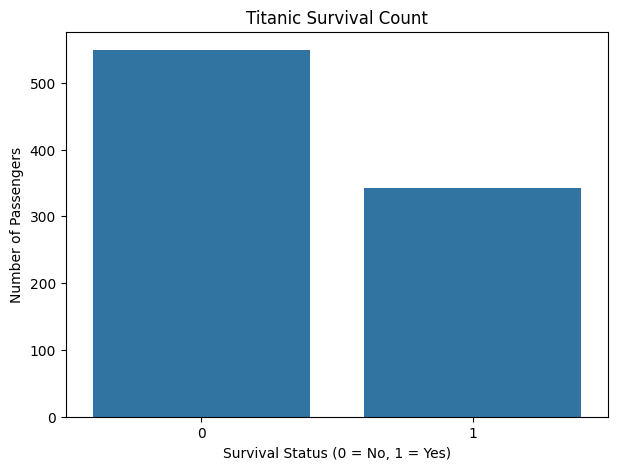

In [35]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df_clean, x="Survived")

plt.title("Titanic Survival Count")
plt.xlabel("Survival Status (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")

plt.show()

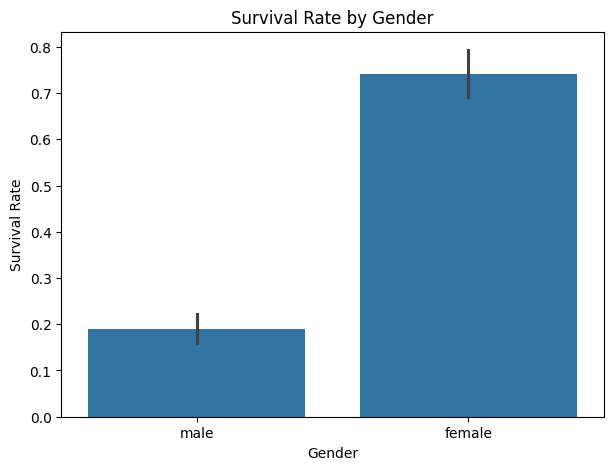

In [36]:
plt.figure(figsize=(7, 5))

sns.barplot(data=df_clean, x="Sex", y="Survived")

plt.title("Survival Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Survival Rate")

plt.show()

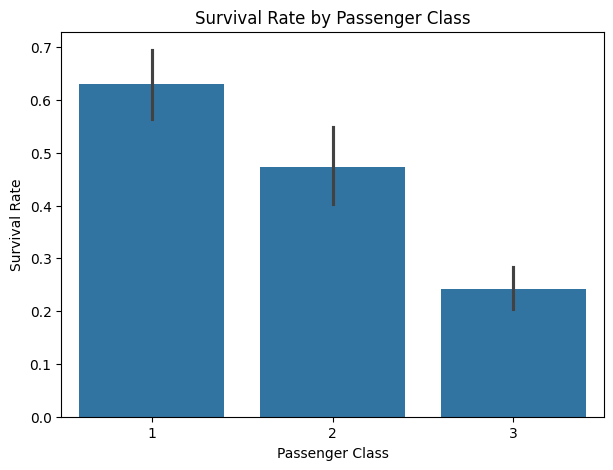

In [37]:
plt.figure(figsize=(7, 5))

sns.barplot(data=df_clean, x="Pclass", y="Survived")

plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate")

plt.show()

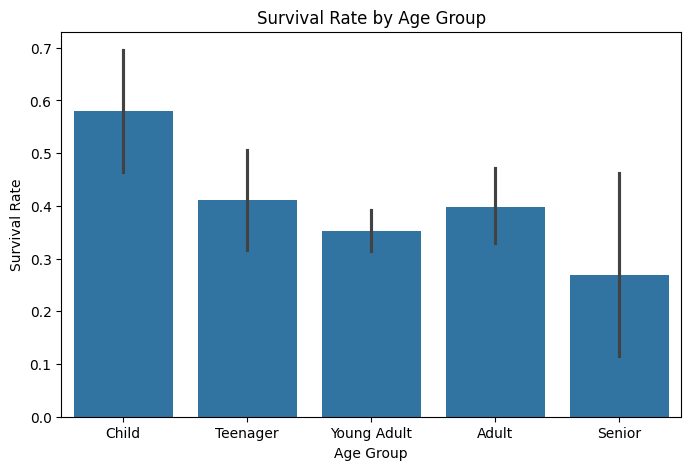

In [38]:
plt.figure(figsize=(8, 5))

sns.barplot(data=df_clean, x="AgeGroup", y="Survived")

plt.title("Survival Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Survival Rate")

plt.show()


## Key Findings

### 1. Overall Survival
Out of 891 passengers, 342 survived (38.38%), while 549 did not survive (61.62%).

### 2. Survival by Gender
Female passengers had a survival rate of 74.20%, compared with 18.89% for male passengers. Female passengers had a substantially higher observed survival rate.

### 3. Survival by Passenger Class
First-class passengers had the highest survival rate (62.96%), followed by second-class passengers (47.28%) and third-class passengers (24.24%).

### 4. Survival by Age Group
Children had the highest survival rate (57.97%), while seniors had the lowest (26.92%). Young adults represented the largest age group in the dataset.


## Limitations

- Some passenger age values were missing and were replaced with the median age of 28.
- Passengers with missing ages were assigned to the Young Adult category after age-group creation.
- The Cabin column was excluded due to a large proportion of missing values.
- The analysis identifies patterns and associations but does not prove causation.
- This analysis uses the available Titanic training dataset.


## Final Data Quality Check

After cleaning and analysis, we verify the final dataset for missing values and duplicate records.


In [41]:
print("Final dataset shape:", df_clean.shape)

print("\nMissing values:")
print(df_clean.isnull().sum())

print("\nDuplicate rows:", df_clean.duplicated().sum())

Final dataset shape: (891, 12)

Missing values:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
AgeGroup       0
dtype: int64

Duplicate rows: 0
